# Prediksi Klasifikasi Usia Konten Netflix (Netflix Content Rating Prediction)
**Assignment 1: Ready-to-Use Data**  
*Mata Kuliah: Applied Artificial Intelligence*

---

## 1. Problem and Data Description

### 1.1 Business Problem (Masalah Bisnis)
Netflix memiliki ribuan judul film dan serial TV dari berbagai negara dengan kategori usia penonton yang beragam. Klasifikasi usia (*age rating*) merupakan informasi krusial untuk:
1. **Parental Control**: Membantu orang tua menyaring tayangan yang aman dan sesuai untuk anak-anak.
2. **Sistem Rekomendasi**: Menyesuaikan katalog tontonan dengan profil usia akun pengguna.
3. **Efisiensi Kurasi**: Menentukan klasifikasi usia secara otomatis pada konten baru berdasarkan metadata judul sebelum ditayangkan.

**Tujuan Pemodelan (Prediction Goal):**  
Membangun model Machine Learning berbasis klasifikasi multikelas untuk memprediksi klasifikasi usia (`rating`) konten Netflix berdasarkan metadata yang tersedia, seperti jenis konten (`type`), tahun rilis (`release_year`), genre (`listed_in`), dan durasi (`duration`).

---

### 1.2 Dataset Source (Sumber Dataset)
Dataset yang digunakan berasal dari platform open data **Kaggle**:  
[Netflix Movies and TV Shows](https://www.kaggle.com/datasets/shivamb/netflix-shows/data) yang dikurasi oleh Shivam Bansal.

---

### 1.3 Meaning of Each Column (Kamus Data)
Dataset ini terdiri dari 12 kolom dengan rincian sebagai berikut:

| Nama Kolom | Tipe Data | Deskripsi / Arti Kolom |
| :--- | :--- | :--- |
| `show_id` | Teks (Objek) | Identitas unik untuk setiap judul film atau TV show |
| `type` | Kategorikal | Kategori tayangan, yaitu **Movie** atau **TV Show** *(Kandidat Fitur)* |
| `title` | Teks | Judul resmi dari film atau TV show |
| `director` | Teks | Nama sutradara yang mengarahkan tayangan |
| `cast` | Teks | Daftar nama aktor/aktris utama |
| `country` | Teks | Negara tempat konten diproduksi |
| `date_added` | Tanggal | Tanggal saat konten resmi ditambahkan ke katalog Netflix |
| `release_year` | Numerik (Int) | Tahun rilis asli konten di bioskop atau televisi *(Kandidat Fitur)* |
| `rating` | Kategorikal | Klasifikasi usia konten (misal: TV-MA, TV-14, PG-13, R) **[VARIABEL TARGET]** |
| `duration` | Teks | Durasi tayangan dalam menit (Movie) atau season (TV Show) *(Kandidat Fitur)* |
| `listed_in` | Teks | Genre atau kategori konten di Netflix *(Kandidat Fitur)* |
| `description` | Teks | Ringkasan sinopsis cerita dari konten |


In [17]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    plt.style.use('seaborn-v0_8-whitegrid')
except Exception:
    plt.style.use('ggplot')

plt.rcParams.update({
    'font.size': 11,
    'figure.titlesize': 14,
    'axes.titlesize': 13,
    'axes.labelsize': 11
})

if os.path.exists('netflix_titles.csv'):
    df = pd.read_csv('netflix_titles.csv')
elif os.path.exists('/content/archive (1).zip'):
    with zipfile.ZipFile('/content/archive (1).zip') as z:
        df = pd.read_csv(z.open('netflix_titles.csv'))
elif os.path.exists('archive (1).zip'):
    with zipfile.ZipFile('archive (1).zip') as z:
        df = pd.read_csv(z.open('netflix_titles.csv'))
else:
    df = pd.read_csv('netflix_titles.csv')

print(f"Ukuran Dataset: {df.shape[0]} baris, {df.shape[1]} kolom")
df.head(3)


Ukuran Dataset: 8807 baris, 12 kolom


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...


In [18]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


## 2. Exploratory Data Analysis (EDA)


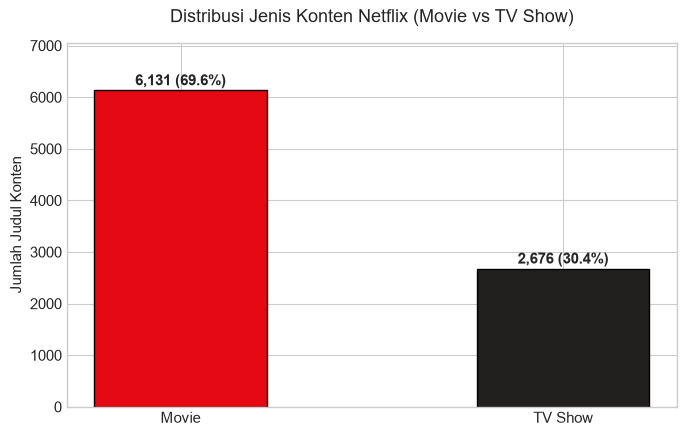

In [19]:
# Distribusi Jenis Konten (Movie vs TV Show)
type_counts = df['type'].value_counts()
colors = ['#E50914', '#221F1F']

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(type_counts.index, type_counts.values, color=colors, width=0.45, edgecolor='black')

total = len(df)
for bar in bars:
    yval = bar.get_height()
    pct = (yval / total) * 100
    ax.text(bar.get_x() + bar.get_width() / 2, yval + 100, f"{yval:,} ({pct:.1f}%)", ha='center', fontweight='bold')

ax.set_title('Distribusi Jenis Konten Netflix (Movie vs TV Show)', pad=15)
ax.set_ylabel('Jumlah Judul Konten')
ax.set_ylim(0, type_counts.max() * 1.15)
plt.tight_layout()
plt.show()


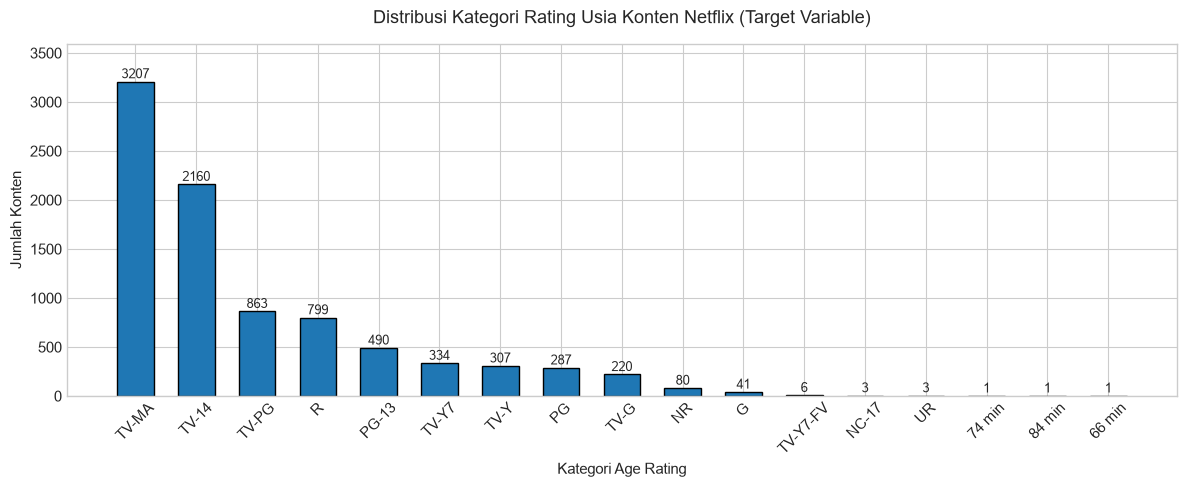

In [20]:
# Distribusi Target Variabel (Rating)
rating_counts = df['rating'].value_counts()

plt.figure(figsize=(12, 5))
bars = plt.bar(rating_counts.index, rating_counts.values, color='#1f77b4', edgecolor='black', width=0.6)
plt.title('Distribusi Kategori Rating Usia Konten Netflix (Target Variable)', pad=15)
plt.xlabel('Kategori Age Rating')
plt.ylabel('Jumlah Konten')
plt.xticks(rotation=45)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, yval + 35, str(yval), ha='center', fontsize=9)

plt.ylim(0, rating_counts.max() * 1.12)
plt.tight_layout()
plt.show()


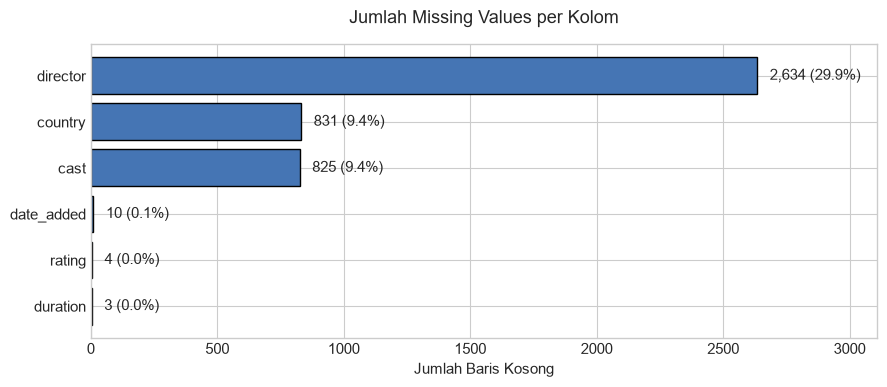

In [21]:
# Analisis Missing Values per Kolom
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=True)

plt.figure(figsize=(9, 4))
bars = plt.barh(missing.index, missing.values, color='#4575b4', edgecolor='black')

for bar in bars:
    xval = bar.get_width()
    pct = (xval / len(df)) * 100
    plt.text(xval + 50, bar.get_y() + bar.get_height()/2, f"{xval:,} ({pct:.1f}%)", va='center')

plt.title('Jumlah Missing Values per Kolom', pad=15)
plt.xlabel('Jumlah Baris Kosong')
plt.xlim(0, missing.max() * 1.18)
plt.tight_layout()
plt.show()


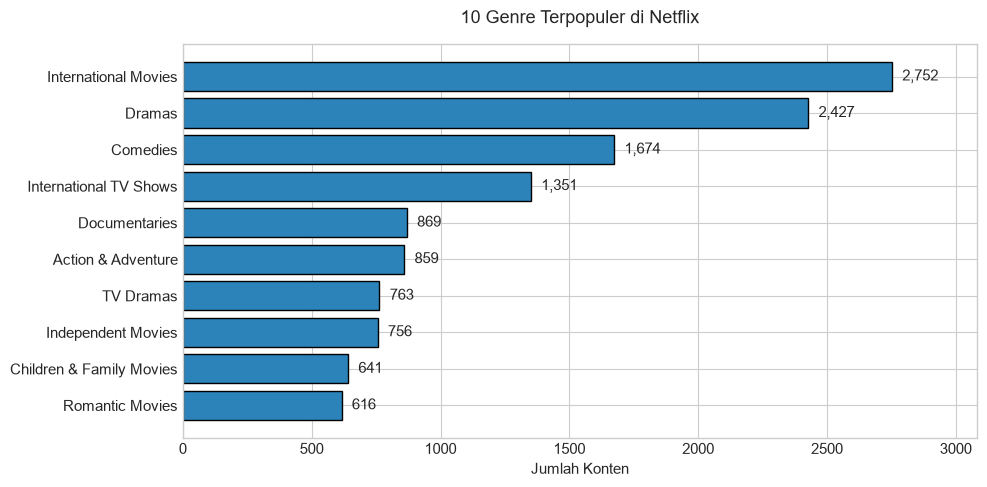

In [22]:
# 10 Genre Terpopuler di Netflix
genres = df['listed_in'].dropna().str.split(', ').explode()
top_genres = genres.value_counts().head(10).sort_values(ascending=True)

plt.figure(figsize=(10, 5))
bars = plt.barh(top_genres.index, top_genres.values, color='#2b83ba', edgecolor='black')

for bar in bars:
    plt.text(bar.get_width() + 40, bar.get_y() + bar.get_height()/2, f"{bar.get_width():,}", va='center')

plt.title('10 Genre Terpopuler di Netflix', pad=15)
plt.xlabel('Jumlah Konten')
plt.xlim(0, top_genres.max() * 1.12)
plt.tight_layout()
plt.show()


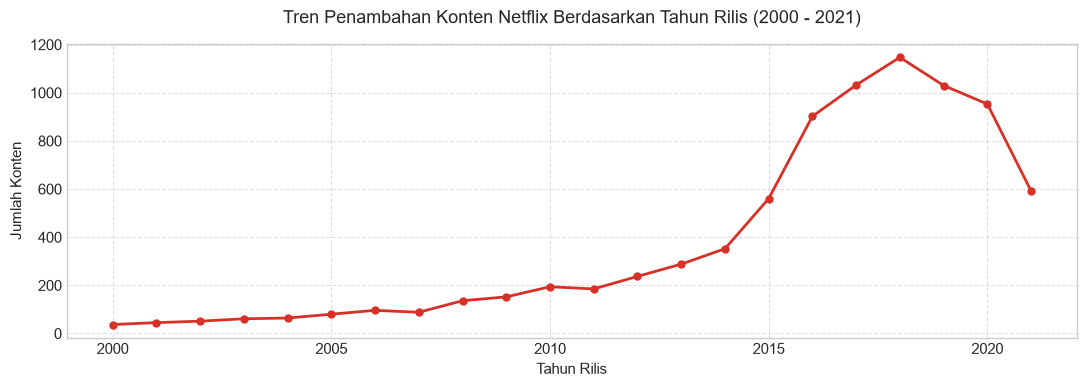

In [23]:
# Tren Produksi Konten Berdasarkan Tahun Rilis (2000 - 2021)
recent_years = df[df['release_year'] >= 2000]['release_year'].value_counts().sort_index()

plt.figure(figsize=(11, 4))
plt.plot(recent_years.index, recent_years.values, marker='o', color='#d73027', linewidth=2, markersize=5)
plt.title('Tren Penambahan Konten Netflix Berdasarkan Tahun Rilis (2000 - 2021)', pad=15)
plt.xlabel('Tahun Rilis')
plt.ylabel('Jumlah Konten')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


## 3. Data Cleaning

- **Missing Values**: Menghapus baris tanpa target `rating` dan mengisi fitur kategorikal dengan `'Unknown'`.
- **Target Validation**: Menghapus nilai rating anomali yang berisi format durasi menit.
- **Duplicates**: Memeriksa dan menghapus baris duplikat.
- **Duration Extraction**: Memisahkan nilai angka (`duration_value`) dan satuan (`duration_unit`).
- **Encoding & Scaling**: Menggunakan OneHotEncoder untuk fitur kategorikal dan StandardScaler untuk fitur numerik yang dirangkum di dalam Pipeline untuk mencegah data leakage.


In [24]:
df_clean = df.copy()

# 1. Hapus missing values pada target rating & anomali format durasi
df_clean = df_clean.dropna(subset=['rating']).copy()
invalid_ratings = df_clean['rating'].astype(str).str.fullmatch(r'\d+\s*min')
df_clean = df_clean.loc[~invalid_ratings].copy()

# 2. Imputasi fitur kategorikal
df_clean['type'] = df_clean['type'].fillna('Unknown')
df_clean['listed_in'] = df_clean['listed_in'].fillna('Unknown')

# 3. Cek dan drop duplikat
print("Jumlah data duplikat:", df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates()

# 4. Ekstraksi fitur durasi
df_clean['duration_value'] = pd.to_numeric(
    df_clean['duration'].str.extract(r'(\d+)')[0],
    errors='coerce'
)
df_clean['duration_unit'] = df_clean['duration'].str.extract(
    r'(min|Seasons?)',
    expand=False
).fillna('Unknown')

print(f"Ukuran dataset setelah data cleaning: {df_clean.shape[0]} baris, {df_clean.shape[1]} kolom")
df_clean[['type', 'duration', 'duration_value', 'duration_unit', 'rating']].head(5)


Jumlah data duplikat: 0
Ukuran dataset setelah data cleaning: 8800 baris, 14 kolom


,type,duration,duration_value,duration_unit,rating
0,Movie,90 min,90,min,PG-13
1,TV Show,2 Seasons,2,Seasons,TV-MA
2,TV Show,1 Season,1,Season,TV-MA
3,TV Show,1 Season,1,Season,TV-MA
4,TV Show,2 Seasons,2,Seasons,TV-MA


## 4. Train/Test Split & Machine Learning Pipeline


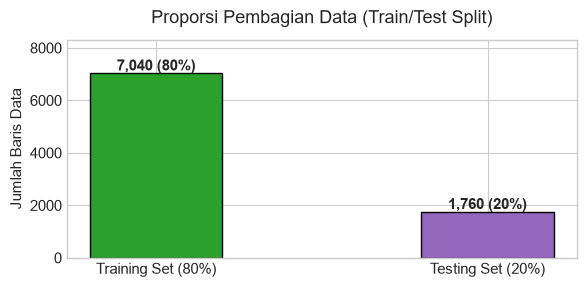

In [25]:
from sklearn.model_selection import train_test_split

features = ['type', 'release_year', 'duration_value', 'duration_unit', 'listed_in']
X = df_clean[features]
y = df_clean['rating']

# Stratified Split 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

fig, ax = plt.subplots(figsize=(6, 3))
bars = ax.bar(['Training Set (80%)', 'Testing Set (20%)'], [len(X_train), len(X_test)], color=['#2ca02c', '#9467bd'], width=0.4, edgecolor='black')

for bar in bars:
    h = bar.get_height()
    pct = (h / len(X)) * 100
    ax.text(bar.get_x() + bar.get_width()/2, h + 100, f"{h:,} ({pct:.0f}%)", ha='center', fontweight='bold')

ax.set_title('Proporsi Pembagian Data (Train/Test Split)', pad=12)
ax.set_ylabel('Jumlah Baris Data')
ax.set_ylim(0, len(X_train) * 1.18)
plt.tight_layout()
plt.show()


In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

num_features = ['release_year', 'duration_value']
cat_features = ['type', 'duration_unit', 'listed_in']

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, num_features),
    ('cat', categorical_transformer, cat_features)
])

model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

# Training model
model_pipeline.fit(X_train, y_train)
y_pred = model_pipeline.predict(X_test)
print("Model Pipeline berhasil dilatih!")


Model Pipeline berhasil dilatih!


## 5. Model Evaluation


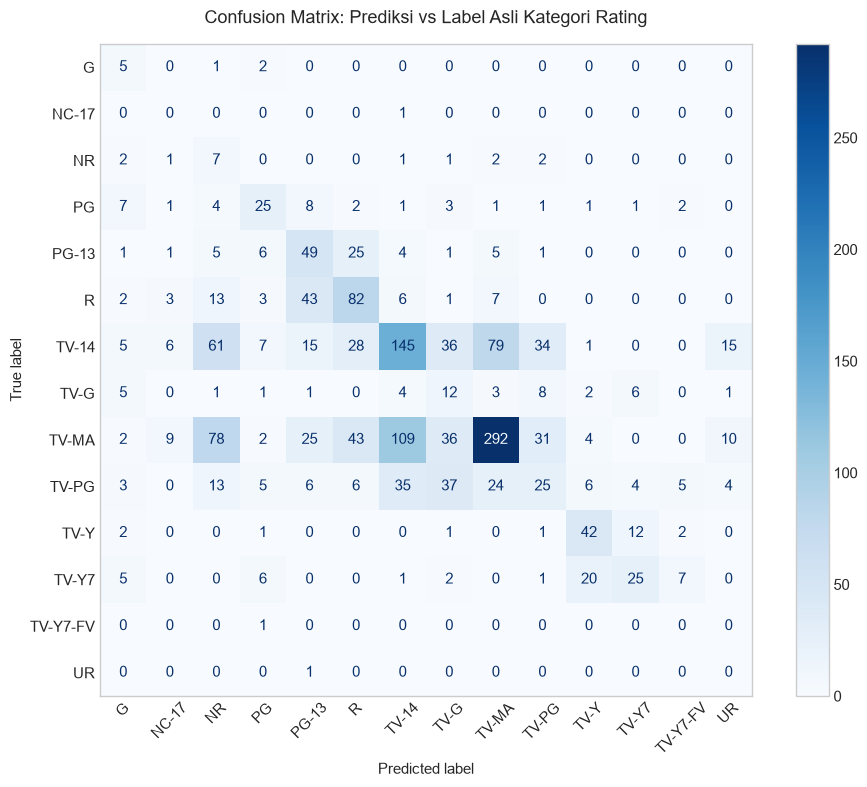

In [27]:
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report

labels = sorted(y.unique())

fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=labels,
    cmap='Blues',
    xticks_rotation=45,
    ax=ax,
    colorbar=True
)
ax.set_title('Confusion Matrix: Prediksi vs Label Asli Kategori Rating', pad=15)
ax.grid(False)
plt.tight_layout()
plt.show()


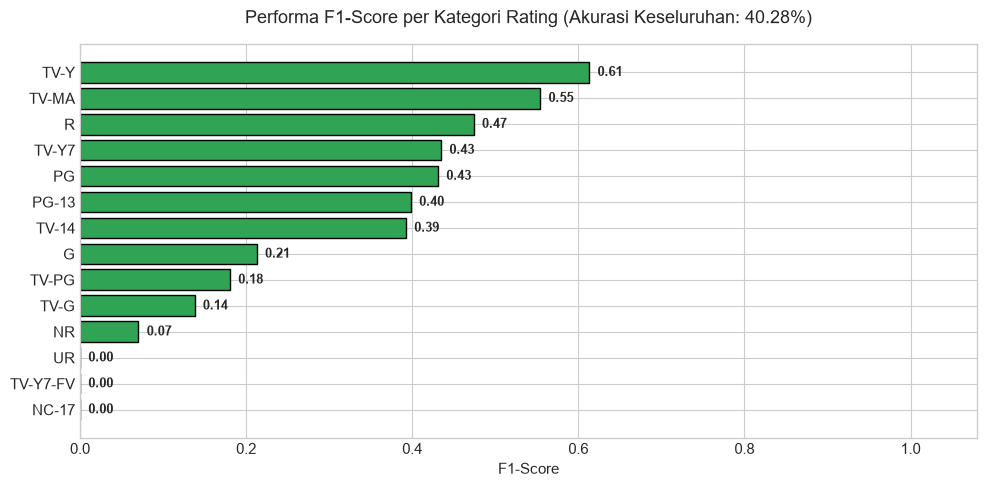

In [28]:
report_dict = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
categories = [label for label in labels if label in report_dict]
f1_scores = [report_dict[cat]['f1-score'] for cat in categories]

perf_df = pd.DataFrame({'Rating': categories, 'F1-Score': f1_scores}).sort_values('F1-Score', ascending=True)

plt.figure(figsize=(10, 5))
bars = plt.barh(perf_df['Rating'], perf_df['F1-Score'], color='#31a354', edgecolor='black')

for bar in bars:
    val = bar.get_width()
    plt.text(val + 0.01, bar.get_y() + bar.get_height()/2, f"{val:.2f}", va='center', fontweight='bold', fontsize=9)

acc = accuracy_score(y_test, y_pred)
plt.title(f'Performa F1-Score per Kategori Rating (Akurasi Keseluruhan: {acc*100:.2f}%)', pad=15)
plt.xlabel('F1-Score')
plt.xlim(0, 1.08)
plt.tight_layout()
plt.show()
